# Bài thực hành: Cài đặt Bộ phân lớp tuyến tính

**Perceptron, Logistic Regression, SVM tuyến tính. So sánh hiệu năng trên nhiều tập dữ liệu.**

> Điền vào các ô có `# TODO`, xóa dòng `raise NotImplementedError` tương ứng, rồi chạy lại toàn bộ notebook (Kernel → Restart & Run All) trước khi nộp.
>
> Họ tên: ................................ MSSV: ................................

## 0. Mục tiêu và chuẩn bị

**Mục tiêu.** :
- tự cài đặt bằng NumPy ba bộ phân lớp tuyến tính: Perceptron, Logistic Regression, SVM tuyến tính;
- mở rộng bộ phân lớp nhị phân sang đa lớp bằng one-vs-rest;
- so sánh độ chính xác, tốc độ hội tụ và ranh giới quyết định trên nhiều tập dữ liệu;
- đối chiếu cài đặt của mình với scikit-learn (bài tập về nhà).

| Phần | Nội dung | Hình thức |
|---|---|---|
| 1 | Dữ liệu, chia tập, chuẩn hóa | Trên lớp |
| 2 | Cài đặt bằng NumPy | Trên lớp |
| 3 | So sánh các cài đặt NumPy | Trên lớp |
| 4 | Đối chiếu với scikit-learn | Bài tập về nhà |
| 5 | Câu hỏi thảo luận | Trên lớp và về nhà |

**Thư viện.** Ở Phần 1 đến 3, thuật toán chỉ được viết bằng NumPy. scikit-learn chỉ dùng để tải dữ liệu, chia tập và tính độ đo; pandas chỉ dùng để hiển thị bảng.

**Quy ước ký hiệu.**
- $\mathbf{x} \in \mathbb{R}^d$ là vectơ đặc trưng; $\tilde{\mathbf{x}} = [\mathbf{x}; 1] \in \mathbb{R}^{d+1}$ là vectơ mở rộng, nên bias là thành phần cuối của $\mathbf{w}$.
- Hàm quyết định tuyến tính $g(\mathbf{x}) = \mathbf{w}^\top \tilde{\mathbf{x}}$, dự đoán $\hat{y} = \operatorname{sign}(g(\mathbf{x}))$.
- Nhãn nhị phân $y \in \{-1, +1\}$. Riêng Logistic Regression dùng $t = (y + 1)/2 \in \{0, 1\}$.

Nguồn tham khảo được đánh dấu [n], xem Phần 6.

In [2]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

SEED = 0            # seed chung cho dữ liệu, cách chia tập và thuật toán
TEST_SIZE = 0.3     # tỉ lệ tập test
SEEDS = range(10)   # 10 cách chia khác nhau dùng ở Phần 3.3

# Màu theo lớp, thứ tự cố định; mỗi lớp có thêm ký hiệu điểm riêng
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
CLASS_MARKERS = ["o", "s", "^"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def add_bias(X):
    """Thêm cột 1 vào cuối ma trận: x̃ = [x; 1]."""
    return np.hstack([X, np.ones((X.shape[0], 1))])


def plot_data(ax, X, y, title="", labels=None):
    """Vẽ điểm dữ liệu 2 chiều, mỗi lớp một màu và một ký hiệu."""
    classes = np.unique(y)
    for k, c in enumerate(classes):
        m = y == c
        if labels is not None:
            name = labels[k]
        else:
            name = f"Lớp {c:+d}" if len(classes) == 2 else f"Lớp {c}"
        ax.scatter(X[m, 0], X[m, 1], s=22, c=CLASS_COLORS[k], marker=CLASS_MARKERS[k],
                   edgecolors="white", linewidths=0.5, label=name)
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, frameon=True, facecolor="white", framealpha=0.85, edgecolor="none")


def plot_decision_boundary(ax, model, X, y, title="", show_margin=False, resolution=300):
    """Tô vùng quyết định; với bài toán nhị phân vẽ thêm g(x) = 0 và lề g(x) = ±1."""
    pad = 0.5
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, resolution),
                         np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, resolution))
    grid = np.c_[xx.ravel(), yy.ravel()]
    classes = np.unique(y)
    Z = np.searchsorted(classes, model.predict(grid)).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.arange(len(classes) + 1) - 0.5,
                colors=CLASS_COLORS[:len(classes)], alpha=0.15)
    if len(classes) == 2:
        F = model.decision_function(grid).reshape(xx.shape)
        ax.contour(xx, yy, F, levels=[0], colors="#333333", linewidths=1.2)
        if show_margin:
            ax.contour(xx, yy, F, levels=[-1, 1], colors="#333333", linestyles="--", linewidths=0.8)
    plot_data(ax, X, y, title)
    ax.set_xlabel("$x_1$ (đã chuẩn hóa)", fontsize=9)
    ax.set_ylabel("$x_2$ (đã chuẩn hóa)", fontsize=9)

## 1. Dữ liệu

| Ký hiệu | Mô tả | Số mẫu | Số đặc trưng | Số lớp | Nguồn |
|---|---|---|---|---|---|
| D1 | Hai lớp Gauss tách được tuyến tính | 200 | 2 | 2 | dựa trên [1] |
| D2 | Hai lớp Gauss chồng lấn | 200 | 2 | 2 | [1] |
| D3a | Wine, 2 đặc trưng (alcohol, malic acid) | 178 | 2 | 3 | [1], [7] |
| D3b | Wine, đủ 13 đặc trưng | 178 | 13 | 3 | [1], [7] |

D2 dùng đúng thiết lập trong notebook bài tập `linear_classifiers_exercise` của [1]: $\boldsymbol{\mu}_1 = [1, 1]$, $\boldsymbol{\mu}_2 = [1.5, 1.5]$, $\boldsymbol{\Sigma} = 0.2\mathbf{I}$, 100 mẫu mỗi lớp. D1 giữ nguyên lớp 1 và dời trung bình lớp 2 ra xa đến khi hai lớp tách được, theo gợi ý trong cùng notebook đó. D3a là phiên bản 2 đặc trưng của Wine được [1] dùng làm điểm xuất phát, D3b dùng đủ 13 đặc trưng.

### 1.1 Tạo và tải dữ liệu

In [3]:
rng = np.random.default_rng(SEED)
N_PER_CLASS = 100
SIGMA = np.array([[0.2, 0.0], [0.0, 0.2]])


def make_two_gaussians(mu1, mu2, n, rng):
    """Hai lớp Gauss cùng hiệp phương sai SIGMA. Lớp 1 có nhãn +1, lớp 2 có nhãn −1."""
    X1 = rng.multivariate_normal(mu1, SIGMA, n)
    X2 = rng.multivariate_normal(mu2, SIGMA, n)
    X = np.vstack([X1, X2])
    y = np.hstack([np.ones(n, dtype=int), -np.ones(n, dtype=int)])
    return X, y


X_d1, y_d1 = make_two_gaussians([1.0, 1.0], [3.0, 3.0], N_PER_CLASS, rng)   # D1: tách được
X_d2, y_d2 = make_two_gaussians([1.0, 1.0], [1.5, 1.5], N_PER_CLASS, rng)   # D2: chồng lấn [1]

wine = load_wine()
X_d3b, y_d3 = wine.data, wine.target
X_d3a = X_d3b[:, :2]   # alcohol, malic acid [1]

DATASETS = {
    "D1": (X_d1, y_d1),
    "D2": (X_d2, y_d2),
    "D3a": (X_d3a, y_d3),
    "D3b": (X_d3b, y_d3),
}
for name, (X, y) in DATASETS.items():
    print(f"{name:4s} X có kích thước {X.shape}, các lớp {np.unique(y)}")

D1   X có kích thước (200, 2), các lớp [-1  1]
D2   X có kích thước (200, 2), các lớp [-1  1]
D3a  X có kích thước (178, 2), các lớp [0 1 2]
D3b  X có kích thước (178, 13), các lớp [0 1 2]


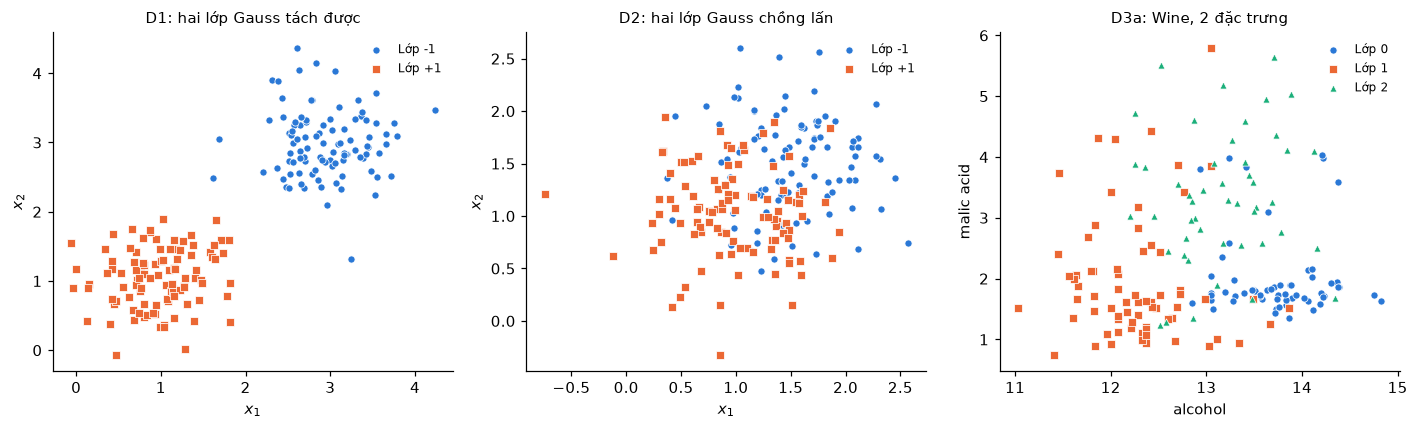

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
plot_data(axes[0], X_d1, y_d1, "D1: hai lớp Gauss tách được")
plot_data(axes[1], X_d2, y_d2, "D2: hai lớp Gauss chồng lấn")
plot_data(axes[2], X_d3a, y_d3, "D3a: Wine, 2 đặc trưng")
for ax in axes[:2]:
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
axes[2].set_xlabel("alcohol"); axes[2].set_ylabel("malic acid")
plt.tight_layout(); plt.show()

### 1.2 Chia tập và chuẩn hóa

Mỗi tập được chia 70% train, 30% test, có phân tầng theo nhãn. Chuẩn hóa z-score

$$x_j \leftarrow \frac{x_j - \mu_j}{\sigma_j},$$

với $\mu_j, \sigma_j$ tính **chỉ trên tập train** rồi áp dụng cho cả train và test, để thông tin của tập test không rò rỉ vào quá trình huấn luyện.

**Nhiệm vụ 1.** Hoàn thành lớp `Standardizer`.

In [9]:
class Standardizer:
    """Chuẩn hóa z-score, tham số học từ tập train."""

    def fit(self, X):
        # TODO: tính self.mean_ và self.std_ theo từng cột; cột có std = 0 thì đặt std = 1
        self.mean_ = np.mean(X, axis=0)
        self.std_ = np.std(X, axis=0)
        self.std_[self.std_ == 0] = 1.0
        return self

    def transform(self, X):
        # TODO: trả về (X − mean) / std
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


def split_and_scale(X, y, seed, scale=True):
    """Chia train/test có phân tầng; chuẩn hóa theo thống kê của tập train."""
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=seed)
    if scale:
        scaler = Standardizer().fit(X_tr)
        X_tr, X_te = scaler.transform(X_tr), scaler.transform(X_te)
    return X_tr, X_te, y_tr, y_te


X_tr, X_te, y_tr, y_te = split_and_scale(X_d3b, y_d3, SEED)
print("Train:", X_tr.shape, "  Test:", X_te.shape)
print("Trung bình 4 cột đầu trên train (≈ 0):    ", np.round(X_tr.mean(axis=0)[:4], 3))
print("Độ lệch chuẩn 4 cột đầu trên train (≈ 1):", np.round(X_tr.std(axis=0)[:4], 3))

Train: (124, 13)   Test: (54, 13)
Trung bình 4 cột đầu trên train (≈ 0):     [0. 0. 0. 0.]
Độ lệch chuẩn 4 cột đầu trên train (≈ 1): [1. 1. 1. 1.]


## 2. Cài đặt bằng NumPy

Mỗi bộ phân lớp là một lớp Python có `fit(X, y)`, `decision_function(X)` trả về $g(\mathbf{x})$ và `predict(X)` trả về nhãn trong $\{-1, +1\}$. Các lớp tự thêm cột bias bằng `add_bias`, nên đầu vào `X` là ma trận đặc trưng gốc.

### 2.1 Perceptron [1], [2]

Perceptron tìm $\mathbf{w}$ sao cho $y_i \mathbf{w}^\top \tilde{\mathbf{x}}_i > 0$ với mọi mẫu. Phiên bản online duyệt các mẫu theo thứ tự ngẫu nhiên; khi gặp mẫu bị phân lớp sai, tức $y_i \mathbf{w}^\top \tilde{\mathbf{x}}_i \le 0$, cập nhật

$$\mathbf{w} \leftarrow \mathbf{w} + \rho\, y_i \tilde{\mathbf{x}}_i,$$

với $\rho > 0$ là hệ số học. Thuật toán dừng khi một epoch không còn mẫu sai, hoặc khi đạt số epoch tối đa.

Nếu dữ liệu tách được tuyến tính, thuật toán hội tụ sau hữu hạn bước [4, mục 4.1.7]. Nếu không, $\mathbf{w}$ dao động mãi và kết quả phụ thuộc vào thời điểm dừng.

**Nhiệm vụ 2.** Hoàn thành vòng cập nhật trong `PerceptronNP.fit`.

In [7]:
class PerceptronNP:
    """Perceptron online [2], nhãn y ∈ {−1, +1}."""

    def __init__(self, rho=1.0, max_epochs=100, shuffle=True, seed=0):
        self.rho = rho
        self.max_epochs = max_epochs
        self.shuffle = shuffle
        self.seed = seed

    def fit(self, X, y):
        Xb = add_bias(X)
        rng = np.random.default_rng(self.seed)
        self.w_ = np.zeros(Xb.shape[1])
        self.errors_ = []                      # số mẫu sai trong từng epoch
        for epoch in range(self.max_epochs):
            order = rng.permutation(len(y)) if self.shuffle else np.arange(len(y))
            #permutation: phép hoán vị
            n_err = 0
            for i in order:
                if y[i] * (self.w_ @ Xb[i]) <= 0:
                    self.w_ = self.w_ + self.rho * y[i] * Xb[i] 
                    n_err += 1
                # TODO: nếu y_i wᵀx̃_i ≤ 0 thì w ← w + ρ y_i x̃_i và tăng n_err
            self.errors_.append(n_err)
            if n_err == 0:
                break
        self.n_epochs_ = len(self.errors_)
        return self

    def decision_function(self, X):
        return add_bias(X) @ self.w_

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

In [10]:
for name in ["D1", "D2"]:
    X, y = DATASETS[name]
    X_tr, X_te, y_tr, y_te = split_and_scale(X, y, SEED)
    p = PerceptronNP(seed=SEED).fit(X_tr, y_tr)
    print(f"{name}: dừng sau {p.n_epochs_:3d} epoch, số mẫu sai ở epoch cuối = {p.errors_[-1]:2d}, "
          f"acc train = {accuracy_score(y_tr, p.predict(X_tr)):.3f}, acc test = {accuracy_score(y_te, p.predict(X_te)):.3f}")

D1: dừng sau   2 epoch, số mẫu sai ở epoch cuối =  0, acc train = 1.000, acc test = 1.000
D2: dừng sau 100 epoch, số mẫu sai ở epoch cuối = 37, acc train = 0.714, acc test = 0.633


### 2.2 Logistic Regression [4]

Tham khảo [4, mục 4.3.2]. Mô hình cho xác suất hậu nghiệm của lớp dương:

$$p(y = +1 \mid \mathbf{x}) = \sigma(z), \qquad z = \mathbf{w}^\top \tilde{\mathbf{x}}, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Với $t_i = (y_i + 1)/2$, hàm mất mát cross entropy có điều chuẩn L2 là

$$J(\mathbf{w}) = \frac{1}{N}\sum_{i=1}^{N} \Big[\log\big(1 + e^{z_i}\big) - t_i z_i\Big] + \frac{\lambda}{2}\big\lVert \mathbf{w}_{1:d} \big\rVert^2 .$$

Biểu thức trong ngoặc bằng $-\big[t_i \log \sigma(z_i) + (1 - t_i)\log(1 - \sigma(z_i))\big]$, viết lại để tính ổn định bằng `np.logaddexp(0, z)`.Gradient:

$$\nabla J = \frac{1}{N}\tilde{\mathbf{X}}^\top(\mathbf{p} - \mathbf{t}) + \lambda\, \mathbf{m} \odot \mathbf{w}, \qquad \mathbf{p} = \sigma(\tilde{\mathbf{X}}\mathbf{w}), \quad \mathbf{m} = [1, \dots, 1, 0].$$

Cập nhật gradient descent: $\mathbf{w} \leftarrow \mathbf{w} - \eta \nabla J$. Hàm $J$ lồi, nên với $\eta$ đủ nhỏ thuật toán hội tụ về nghiệm tối ưu kể cả khi dữ liệu không tách được.

**Nhiệm vụ 3.** Hoàn thành một bước lặp trong `LogisticRegressionNP.fit`.

In [ ]:
def sigmoid(z):
    """σ(z) tính ổn định số học cho cả z rất lớn và rất âm."""
    out = np.empty_like(z, dtype=float)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out


class LogisticRegressionNP:
    """Logistic Regression nhị phân, gradient descent, điều chuẩn L2 (không phạt bias) [4]."""

    def __init__(self, eta=0.5, lam=1e-3, max_epochs=2000, tol=1e-7):
        self.eta = eta
        self.lam = lam
        self.max_epochs = max_epochs
        self.tol = tol

    def fit(self, X, y):
        Xb = add_bias(X)
        t = (y > 0).astype(float)              # {−1, +1} → {0, 1}
        N, d = Xb.shape
        mask = np.ones(d)
        mask[-1] = 0.0                         # không điều chuẩn bias
        self.w_ = np.zeros(d)
        self.loss_ = []                        # J(w) sau từng epoch
        for epoch in range(self.max_epochs):
            # TODO: z = X̃w, p = σ(z); tính loss = J(w), grad = ∇J; cập nhật w ← w − η·grad
            raise NotImplementedError
            self.loss_.append(loss)
            if epoch > 0 and abs(self.loss_[-2] - loss) < self.tol:
                break
        return self

    def decision_function(self, X):
        return add_bias(X) @ self.w_

    def predict_proba(self, X):
        """Xác suất p(y = +1 | x)."""
        return sigmoid(self.decision_function(X))

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

In [ ]:
for name in ["D1", "D2"]:
    X, y = DATASETS[name]
    X_tr, X_te, y_tr, y_te = split_and_scale(X, y, SEED)
    lr = LogisticRegressionNP().fit(X_tr, y_tr)
    print(f"{name}: {len(lr.loss_):4d} epoch, J cuối = {lr.loss_[-1]:.4f}, "
          f"acc test = {accuracy_score(y_te, lr.predict(X_te)):.3f}, "
          f"p(y=+1|x) của 3 mẫu test đầu = {np.round(lr.predict_proba(X_te[:3]), 3)}")

### 2.3 SVM tuyến tính [1], [3], [5]

SVM chọn siêu phẳng có lề lớn nhất. Lý thuyết lề, điều kiện KKT, bài toán đối ngẫu và support vectors được trình bày trong notebook `support_vector_machine` của [1]; xem thêm [3] và [4, mục 7.1]. Ở đây ta giải bài toán **lề mềm** dạng primal:

$$\min_{\mathbf{w}} \; \frac{\lambda}{2}\lVert \mathbf{w} \rVert^2 + \frac{1}{N}\sum_{i=1}^{N} \max\big(0,\; 1 - y_i \mathbf{w}^\top \tilde{\mathbf{x}}_i\big).$$

Số hạng thứ hai là hinge loss. Bài toán tương đương dạng $\tfrac{1}{2}\lVert\mathbf{w}\rVert^2 + C\sum_i \xi_i$ trong [3] khi $C = 1/(\lambda N)$.

**Pegasos [5].** Ở bước $t$, chọn ngẫu nhiên mini batch $A_t$ gồm $k$ mẫu, đặt $\eta_t = 1/(\lambda t)$ và gọi $A_t^+ = \{i \in A_t : y_i \mathbf{w}^\top \tilde{\mathbf{x}}_i < 1\}$ là các mẫu vi phạm lề. Cập nhật theo subgradient, sau đó chiếu $\mathbf{w}$ về hình cầu bán kính $1/\sqrt{\lambda}$:

$$\mathbf{w} \leftarrow (1 - \eta_t \lambda)\,\mathbf{w} + \frac{\eta_t}{k}\sum_{i \in A_t^+} y_i \tilde{\mathbf{x}}_i, \qquad \mathbf{w} \leftarrow \min\Big(1,\; \frac{1/\sqrt{\lambda}}{\lVert \mathbf{w} \rVert}\Big)\,\mathbf{w}.$$

**Lưu ý.** Để đơn giản, bias được gộp vào $\mathbf{w}$ nên cũng bị điều chuẩn; đây là điểm khác so với công thức chuẩn trong [3] (xem câu hỏi thảo luận 6).

Sau khi huấn luyện, các mẫu có $y_i\, g(\mathbf{x}_i) \le 1$ nằm trên hoặc bên trong lề; đó là các support vectors (xấp xỉ, vì Pegasos chỉ cho nghiệm gần đúng). Độ rộng lề là $2/\lVert \mathbf{w}_{1:d} \rVert$.

**Nhiệm vụ 4.** Hoàn thành một bước lặp Pegasos trong `LinearSVMNP.fit`.

In [ ]:
class LinearSVMNP:
    """SVM tuyến tính lề mềm, giải dạng primal bằng Pegasos mini batch [5]."""

    def __init__(self, lam=1e-2, n_iters=3000, batch_size=16, project=True, seed=0, log_every=10):
        self.lam = lam
        self.n_iters = n_iters
        self.batch_size = batch_size
        self.project = project
        self.seed = seed
        self.log_every = log_every

    def objective(self, Xb, y):
        """Hàm mục tiêu (λ/2)‖w‖² + trung bình hinge loss."""
        hinge = np.maximum(0.0, 1.0 - y * (Xb @ self.w_))
        return 0.5 * self.lam * self.w_ @ self.w_ + hinge.mean()

    def fit(self, X, y):
        Xb = add_bias(X)
        N, d = Xb.shape
        k = min(self.batch_size, N)
        rng = np.random.default_rng(self.seed)
        self.w_ = np.zeros(d)
        self.obj_ = []                         # (t, hàm mục tiêu trên toàn tập train)
        for t in range(1, self.n_iters + 1):
            idx = rng.choice(N, size=k, replace=False)
            Xt, yt = Xb[idx], y[idx]
            # TODO: η_t = 1/(λt); tìm mẫu vi phạm lề (y wᵀx̃ < 1); cập nhật w; nếu self.project thì chiếu về ‖w‖ ≤ 1/√λ
            raise NotImplementedError
            if t == 1 or t % self.log_every == 0:
                self.obj_.append((t, self.objective(Xb, y)))
        return self

    def decision_function(self, X):
        return add_bias(X) @ self.w_

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

    def support_vector_mask(self, X, y, tol=1e-3):
        """Mẫu nằm trên hoặc bên trong lề: y g(x) ≤ 1."""
        return y * self.decision_function(X) <= 1.0 + tol

    def margin_width(self):
        return 2.0 / np.linalg.norm(self.w_[:-1])

In [ ]:
for name in ["D1", "D2"]:
    X, y = DATASETS[name]
    X_tr, X_te, y_tr, y_te = split_and_scale(X, y, SEED)
    svm = LinearSVMNP(seed=SEED).fit(X_tr, y_tr)
    n_sv = svm.support_vector_mask(X_tr, y_tr).sum()
    print(f"{name}: mục tiêu cuối = {svm.obj_[-1][1]:.4f}, số support vectors = {n_sv:3d}/{len(y_tr)}, "
          f"độ rộng lề = {svm.margin_width():.3f}, acc test = {accuracy_score(y_te, svm.predict(X_te)):.3f}")

### 2.4 Mở rộng đa lớp: one-vs-rest

Với $K$ lớp, huấn luyện $K$ bộ phân lớp nhị phân; bộ thứ $k$ coi lớp $k$ là $+1$, mọi lớp khác là $-1$. Mẫu mới được gán vào lớp có hàm quyết định lớn nhất:

$$\hat{y} = \arg\max_{k} \; g_k(\mathbf{x}).$$

**Nhiệm vụ 5.** Hoàn thành `OneVsRest.fit` và `OneVsRest.predict`.

In [ ]:
class OneVsRest:
    """Bọc một bộ phân lớp nhị phân thành bộ phân lớp đa lớp."""

    def __init__(self, make_model):
        self.make_model = make_model           # hàm không đối số, trả về một bộ phân lớp nhị phân mới

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.models_ = []
        for c in self.classes_:
            y_bin = np.where(y == c, 1, -1)
            self.models_.append(self.make_model().fit(X, y_bin))
        return self

    def decision_function(self, X):
        return np.column_stack([m.decision_function(X) for m in self.models_])

    def predict(self, X):
        # trả về lớp có giá trị hàm quyết định lớn nhất
        return self.classes_[np.argmax(self.decision_function(X), axis=1)]

# Siêu tham số dùng chung cho toàn bài (Phần 4 dùng lại)
PERC_RHO, PERC_EPOCHS = 1.0, 100
LR_ETA, LAM_LR, LR_EPOCHS = 0.5, 1e-3, 2000
LAM_SVM, SVM_ITERS, SVM_BATCH = 1e-2, 3000, 16

MODEL_FACTORIES = {
    "Perceptron": lambda seed: PerceptronNP(rho=PERC_RHO, max_epochs=PERC_EPOCHS, seed=seed),
    "Logistic Regression": lambda seed: LogisticRegressionNP(eta=LR_ETA, lam=LAM_LR, max_epochs=LR_EPOCHS),
    "SVM tuyến tính": lambda seed: LinearSVMNP(lam=LAM_SVM, n_iters=SVM_ITERS, batch_size=SVM_BATCH, seed=seed),
}
MODEL_NAMES = list(MODEL_FACTORIES)


def make_classifier(model_name, y, seed=SEED):
    """Tạo bộ phân lớp NumPy; tự bọc bằng OneVsRest nếu có hơn 2 lớp."""
    factory = lambda: MODEL_FACTORIES[model_name](seed)
    return OneVsRest(factory) if len(np.unique(y)) > 2 else factory()


X_tr, X_te, y_tr, y_te = split_and_scale(X_d3b, y_d3, SEED)
for m in MODEL_NAMES:
    clf = make_classifier(m, y_tr).fit(X_tr, y_tr)
    print(f"{m:20s} acc test trên D3b = {accuracy_score(y_te, clf.predict(X_te)):.3f}")

## 3. So sánh các cài đặt NumPy

### 3.1 Ranh giới quyết định

Mỗi mô hình được huấn luyện trên tập train (seed 0) của D1, D2, D3a. Hình vẽ điểm train; tiêu đề ghi accuracy trên tập test. Với SVM trên dữ liệu nhị phân, đường nét đứt là lề $g(\mathbf{x}) = \pm 1$ và các điểm được khoanh tròn là support vectors.

In [ ]:
PLOT_SETS = ["D1", "D2", "D3a"]
fitted = {}
fig, axes = plt.subplots(len(PLOT_SETS), len(MODEL_NAMES), figsize=(13, 12))
for r, ds in enumerate(PLOT_SETS):
    X, y = DATASETS[ds]
    X_tr, X_te, y_tr, y_te = split_and_scale(X, y, SEED)
    for c, m in enumerate(MODEL_NAMES):
        clf = make_classifier(m, y_tr).fit(X_tr, y_tr)
        fitted[(ds, m)] = clf
        acc = accuracy_score(y_te, clf.predict(X_te))
        ax = axes[r, c]
        is_binary_svm = m == "SVM tuyến tính" and len(np.unique(y)) == 2
        plot_decision_boundary(ax, clf, X_tr, y_tr, f"{m}, {ds} (acc test = {acc:.2f})", show_margin=is_binary_svm)
        if is_binary_svm:
            sv = clf.support_vector_mask(X_tr, y_tr)
            ax.scatter(X_tr[sv, 0], X_tr[sv, 1], s=90, facecolors="none", edgecolors="#333333",
                       linewidths=0.9, label="support vector")
            ax.legend(fontsize=8, frameon=True, facecolor="white", framealpha=0.85, edgecolor="none")
plt.tight_layout(); plt.show()

Ghi nhận xét về hình trên vào câu 1, 2 của Phần 5.

### 3.2 Hội tụ

So sánh quá trình huấn luyện trên D1 (tách được) và D2 (chồng lấn), dùng các mô hình đã huấn luyện ở 3.1.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for k, ds in enumerate(["D1", "D2"]):
    color = CLASS_COLORS[k]
    p = fitted[(ds, "Perceptron")]
    axes[0].plot(range(1, len(p.errors_) + 1), p.errors_, color=color, lw=2, label=ds)
    lr = fitted[(ds, "Logistic Regression")]
    axes[1].plot(range(1, len(lr.loss_) + 1), lr.loss_, color=color, lw=2, label=ds)
    t, obj = zip(*fitted[(ds, "SVM tuyến tính")].obj_)
    axes[2].plot(t, obj, color=color, lw=2, label=ds)
axes[0].set(title="Perceptron: số mẫu sai mỗi epoch", xlabel="epoch", ylabel="số mẫu sai")
axes[1].set(title="Logistic Regression: J(w)", xlabel="epoch (thang log)", ylabel="J(w)", xscale="log")
axes[2].set(title="SVM (Pegasos): hàm mục tiêu", xlabel="bước lặp t (thang log)", ylabel="mục tiêu", xscale="log")
for ax in axes:
    ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### 3.3 Bảng so sánh trên nhiều lần chia

Lặp lại với 10 cách chia train/test khác nhau (seed 0 đến 9). Báo cáo trung bình ± độ lệch chuẩn của accuracy và F1 macro trên tập test, cùng thời gian huấn luyện.

In [ ]:
def evaluate(model_name, ds_name, seed, scale=True):
    """Huấn luyện một mô hình NumPy trên một cách chia, trả về các độ đo trên tập test."""
    X, y = DATASETS[ds_name]
    X_tr, X_te, y_tr, y_te = split_and_scale(X, y, seed, scale=scale)
    clf = make_classifier(model_name, y_tr, seed)
    t0 = time.perf_counter()
    clf.fit(X_tr, y_tr)
    train_ms = 1000 * (time.perf_counter() - t0)
    y_pred = clf.predict(X_te)
    return {"impl": "NumPy", "dataset": ds_name, "model": model_name, "seed": seed,
            "accuracy": accuracy_score(y_te, y_pred),
            "f1_macro": f1_score(y_te, y_pred, average="macro"),
            "train_ms": train_ms}


def summarize(df, metric, by="dataset", digits=3):
    """Bảng 'trung bình ± độ lệch chuẩn', hàng theo `by`, cột theo mô hình."""
    g = df.groupby([by, "model"], sort=False)[metric]
    cell = g.mean().map(lambda v: f"{v:.{digits}f}") + " ± " + g.std().map(lambda v: f"{v:.{digits}f}")
    return cell.unstack("model")[MODEL_NAMES]


results_np = pd.DataFrame([evaluate(m, ds, s) for ds in DATASETS for m in MODEL_NAMES for s in SEEDS])
print("Accuracy trên tập test");      display(summarize(results_np, "accuracy"))
print("F1 macro trên tập test");      display(summarize(results_np, "f1_macro"))
print("Thời gian huấn luyện (ms)");   display(summarize(results_np, "train_ms", digits=1))

### 3.4 Ảnh hưởng của chuẩn hóa

Các đặc trưng của Wine có thang đo rất khác nhau. Chạy lại ba mô hình trên D3b, có và không có chuẩn hóa.

In [ ]:
print("Khoảng giá trị của một số đặc trưng Wine:")
for j in [12, 4, 10]:
    print(f"  {wine.feature_names[j]:>10s}: {X_d3b[:, j].min():8.2f} đến {X_d3b[:, j].max():8.2f}")

rows = []
for scale in [True, False]:
    for m in MODEL_NAMES:
        for s in SEEDS:
            r = evaluate(m, "D3b", s, scale=scale)
            r["chuẩn hóa"] = "Có" if scale else "Không"
            rows.append(r)
print("\nAccuracy trên tập test của D3b")
display(summarize(pd.DataFrame(rows), "accuracy", by="chuẩn hóa"))

## 4. Bài tập về nhà: đối chiếu với scikit-learn [6]

Dùng lại **đúng các cách chia** ở Phần 3.3 (cùng `TEST_SIZE`, cùng seed, có phân tầng) và chuẩn hóa bằng `StandardScaler`. Ánh xạ siêu tham số, với $N$ là số mẫu train:

| NumPy | scikit-learn | Ghi chú |
|---|---|---|
| `PerceptronNP(rho=1, max_epochs=100)` | `Perceptron(eta0=1.0, max_iter=100, random_state=seed)` | |
| `LogisticRegressionNP(lam=LAM_LR)` | `LogisticRegression(C=1/(LAM_LR·N))` | Đa lớp: bọc bằng `OneVsRestClassifier` để cùng chiến lược với Phần 2.4 |
| `LinearSVMNP(lam=LAM_SVM)` | `LinearSVC(loss="hinge", C=1/(LAM_SVM·N))` | `LinearSVC` mặc định dùng squared hinge |

**Yêu cầu.**
- **4.1** Viết `make_sklearn_classifier` và `evaluate_sklearn`; lập bảng như Phần 3.3 cho scikit-learn.
- **4.2** Ghép kết quả NumPy và scikit-learn thành một bảng so sánh: accuracy trung bình của hai cài đặt, chênh lệch, tỉ lệ thời gian huấn luyện.
- **4.3** Trên D1 và D2 (seed 0), tính cosine similarity giữa $\mathbf{w}$ của bản NumPy và $[\texttt{coef\_}, \texttt{intercept\_}]$ của bản scikit-learn.
- **4.4** Trả lời các câu hỏi giải thích bên dưới.
- **4.5** (Tùy chọn) Lặp lại so sánh trên Spambase [8].

**Nộp:** notebook đã chạy toàn bộ, gồm các bảng ở 4.1 đến 4.3 và câu trả lời 4.4.

### 4.1 Cài đặt bằng scikit-learn

In [ ]:
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler


def make_sklearn_classifier(model_name, n_train, n_classes, seed):
    """Mô hình scikit-learn tương ứng với model_name, cùng siêu tham số với bản NumPy."""
    # TODO: dựa vào bảng ánh xạ ở trên; Logistic Regression đa lớp bọc bằng OneVsRestClassifier
    raise NotImplementedError

In [ ]:
def evaluate_sklearn(model_name, ds_name, seed):
    """Như evaluate() ở Phần 3.3 nhưng dùng StandardScaler và mô hình scikit-learn."""
    # TODO: chia tập như split_and_scale, chuẩn hóa bằng StandardScaler, huấn luyện, đo thời gian, trả về dict cùng khóa với evaluate() và impl = "scikit-learn"
    raise NotImplementedError


results_sk = pd.DataFrame([evaluate_sklearn(m, ds, s) for ds in DATASETS for m in MODEL_NAMES for s in SEEDS])
print("scikit-learn: accuracy trên tập test");    display(summarize(results_sk, "accuracy"))
print("scikit-learn: thời gian huấn luyện (ms)"); display(summarize(results_sk, "train_ms", digits=1))

### 4.2 Bảng so sánh NumPy và scikit-learn

In [ ]:
# TODO: ghép results_np và results_sk; với mỗi (dataset, model) tính accuracy trung bình của hai cài đặt, chênh lệch và tỉ lệ thời gian
raise NotImplementedError

In [ ]:
# TODO: với D1, D2 (seed 0) và từng mô hình, huấn luyện cả hai bản trên cùng dữ liệu chuẩn hóa, tính cosine giữa w và [coef_, intercept_]
raise NotImplementedError

## 5. Câu hỏi thảo luận

1. Trên D1, ba mô hình đều phân lớp tốt nhưng ranh giới khác nhau. Mô hình nào cho lề lớn nhất? Vì sao Perceptron không đảm bảo điều đó?
2. Trên D2, vì sao Perceptron không dừng sớm và kết quả phụ thuộc vào epoch cuối? Logistic Regression và SVM xử lý dữ liệu không tách được như thế nào?
3. Với $\mathbf{w}$ khởi tạo bằng 0, hệ số học $\rho$ của Perceptron có làm thay đổi ranh giới quyết định không? Giải thích.
4. Vì sao chuẩn hóa ảnh hưởng mạnh đến Logistic Regression và SVM ở Phần 3.4?
5. Trong one-vs-rest, các giá trị $g_k(\mathbf{x})$ của Perceptron có so sánh được với nhau không? Đề xuất cách khắc phục.
6. Bản SVM ở đây gộp bias vào $\mathbf{w}$ nên bias cũng bị điều chuẩn. Điều này thay đổi bài toán so với [3] thế nào? Khi nào ảnh hưởng đáng kể?
7. Logistic Regression cho xác suất đầu ra, SVM thì không. Nêu một tình huống điều này quan trọng.
8. So sánh D3a và D3b: thêm đặc trưng làm hiệu năng thay đổi thế nào? Vì sao?

## 6. Tài liệu tham khảo

1. K. Wickström, *Pattern Recognition Handbook*, sổ tay bài giảng học phần FYS-3012 Pattern Recognition, UiT The Arctic University of Norway. GitHub, giấy phép MIT. https://github.com/Wickstrom/pattern-recognition-handbook (thư mục `notebooks/03`, commit `0b0cc6f`, truy cập 11/10/2026). Phần sử dụng: thiết lập D1, D2, D3a và đoạn tải Spambase; cách trình bày Perceptron; lý thuyết SVM (lề, KKT, đối ngẫu, support vectors).
2. F. Rosenblatt, "The perceptron: A probabilistic model for information storage and organization in the brain," *Psychological Review*, vol. 65, no. 6, pp. 386–408, 1958. doi:10.1037/h0042519
3. C. Cortes and V. Vapnik, "Support-vector networks," *Machine Learning*, vol. 20, pp. 273–297, 1995. doi:10.1007/BF00994018
4. C. M. Bishop, *Pattern Recognition and Machine Learning*. Springer, 2006. Mục 4.1.7 (thuật toán Perceptron), 4.3.2 (Logistic Regression), 7.1 (bộ phân lớp lề cực đại).
5. S. Shalev-Shwartz, Y. Singer, N. Srebro, and A. Cotter, "Pegasos: Primal estimated sub-gradient solver for SVM," *Mathematical Programming*, vol. 127, no. 1, pp. 3–30, 2011. doi:10.1007/s10107-010-0420-4
6. F. Pedregosa et al., "Scikit-learn: Machine learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.
7. S. Aeberhard and M. Forina, "Wine," UCI Machine Learning Repository, 1991. doi:10.24432/C5PC7J
8. M. Hopkins, E. Reeber, G. Forman, and J. Suermondt, "Spambase," UCI Machine Learning Repository, 1999. doi:10.24432/C53G6X